<a href="https://colab.research.google.com/github/attaboatengsr/data620/blob/main/data620_project1_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install igraph -q
%pip install matplotlib -q
%pip install seaborn -q
%pip install numpy -q
%pip install pandas -q
%pip install scipy -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 41.0 MB/s eta 0:00:00


In [2]:
import igraph as ig
import matplotlib.pyplot as plt
import scipy.stats as stats
import numpy as np
import pandas as pd
import seaborn as sns
import os

Degree centrality counts the total number of direct connection (edges) a node has.

In this analysis, I am going to examine the Facebook dataset and compare male and female groups.

I assume that female groups will have a degree centrality than male groups. I will find the average degree centrality between the two groups and use t-test for my analysis.

####Motivation:
A company might want to open a social page and would want get an influencer to get more engagement.

####Null hypothesis:
The mean degree centrality between the male and female groups are the same



In [3]:

# 1. Load Edges and Build the Graph
edges_df = pd.read_csv('/content/facebook/0.edges', header=None, sep=' ')
g = ig.Graph.TupleList(edges_df.values, directed=False)

# 2. Load Node Features to Identify Gender
feat_df = pd.read_csv('/content/facebook/0.feat', header=None, sep=' ')

# Identify gender columns from '0.featnames' (e.g., features 77 and 78 typically encode gender in SNAP datasets)
# Let's map node IDs to their respective gender category
gender_labels = {}
for idx, row in feat_df.iterrows():
  node_id = row[0]
  is_male = row[78] == 1 if len(row) > 78 else False
  is_female = row[79] == 1 if len(row) > 79 else False

  if is_male:
    gender_labels[node_id] = 'Male'
  elif is_female:
    gender_labels[node_id] = 'Female'
  else:
    gender_labels[node_id] = 'Unknown'


data = pd.DataFrame({'degree': g.degree(), 'gender': [gender_labels.get(v.index, 'Unknown') for v in g.vs]})

# Filter out unknown/unlabeled nodes
filtered_data = data[data['gender'].isin(['Male', 'Female'])]
display(filtered_data)


,degree,gender
1,86,Male
2,124,Female
3,92,Female
4,30,Female
5,52,Female
...,...,...
328,2,Female
329,2,Female
330,2,Male
331,2,Female


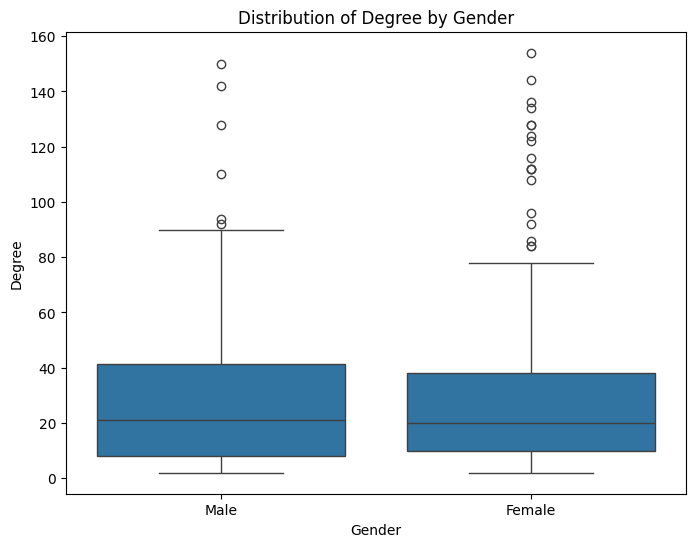

In [4]:
#Visualizing and comparing the distribution between male and females
plt.figure(figsize=(8, 6))
sns.boxplot(x="gender", y="degree", data=filtered_data)
plt.title("Distribution of Degree by Gender")
plt.xlabel("Gender")
plt.ylabel("Degree")
plt.show()

In [5]:
filtered_data.groupby('gender')['degree'].describe()
#

,count,mean,std,min,25%,50%,75%,max
gender,,,,,,,,
Female,204.0,30.343137,31.663562,2.0,10.0,20.0,38.0,154.0
Male,122.0,30.606557,30.547499,2.0,8.0,21.0,41.5,150.0


In [6]:
degree_mean_male = filtered_data[filtered_data['gender'] == 'Male']['degree'].mean()
degree_mean_female = filtered_data[filtered_data['gender'] == 'Female']['degree'].mean()

size_degree_male = filtered_data[filtered_data['gender'] == 'Male']['degree'].count()
size_degree_female = filtered_data[filtered_data['gender'] == 'Female']['degree'].count()

degree_std_male = filtered_data[filtered_data['gender'] == 'Male']['degree'].std()
degree_std_female = filtered_data[filtered_data['gender'] == 'Female']['degree'].std()

t = (degree_mean_male - degree_mean_female) / np.sqrt((degree_std_male**2/size_degree_male) + (degree_std_female**2/size_degree_female) )
df = size_degree_male + size_degree_female - 2

Since the mean of male group (our group 1) is greater than the female group (our group 2), it will be right tail test.

In [7]:
p = 1 - stats.t.cdf(t, df=df)
print('p-value: ',p)

p-value:  0.47040149577627555


Since our p-value is greater than our alpha (0.05), we fail to reject our null hypothesis. There is no statistically significance between the average degree centrality between the two groups.

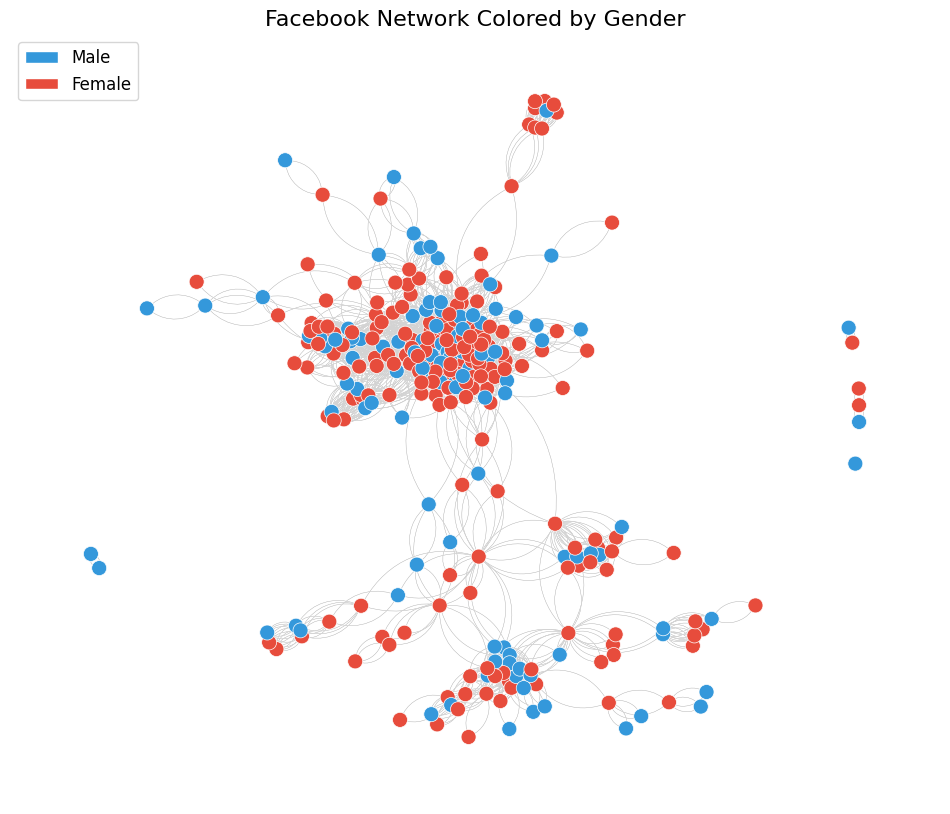

In [10]:
# 1. Assign gender as a vertex attribute on the main graph
for v in g.vs:
    v['gender'] = gender_labels.get(v.index, 'Unknown')

# 2. Create an induced subgraph containing only Male and Female nodes (the filtered dataset)
g_filtered = g.induced_subgraph([v for v in g.vs if v['gender'] in ['Male', 'Female']])

# 3. Assign colors to vertices based on gender
vertex_colors = ['#3498db' if v['gender'] == 'Male' else '#e74c3c' for v in g_filtered.vs]

# 4. Configure plotting layout and styling
layout = g_filtered.layout("fr")  # Fruchterman-Reingold layout

fig, ax = plt.subplots(figsize=(12, 10))

ig.plot(
    g_filtered,
    target=ax,
    layout=layout,
    vertex_size=15,
    vertex_color=vertex_colors,
    vertex_frame_width=0.5,
    vertex_frame_color="white",
    edge_width=0.3,
    edge_color="#d3d3d3"
)

# 5. Create a custom legend for Male and Female
legend_elements = [
    Patch(facecolor='#3498db', edgecolor='white', label='Male'),
    Patch(facecolor='#e74c3c', edgecolor='white', label='Female')
]
ax.legend(handles=legend_elements, loc='upper left', fontsize=12)
plt.title("Facebook Network Colored by Gender", fontsize=16)
plt.axis('off')
plt.show()